# Remove periodic variability with diagnostics

In [1]:
%matplotlib inline

# Import the analysis and plotting tools and record the package version.
import numpy as np
import matplotlib.pyplot as plt
import nahiku
from nahiku import Nahiku
print(f"Nāhiku {nahiku.__version__}")

# Set the display resolution and simplify plot borders.
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

/tmp/nahiku-02/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Nāhiku 0.2.0


  0%|          | 0/3 [00:00<?, ?it/s]

 33%|███▎      | 1/3 [00:00<00:00, 217.01it/s]

Default Balmung: [7.69215245] minimum_snr


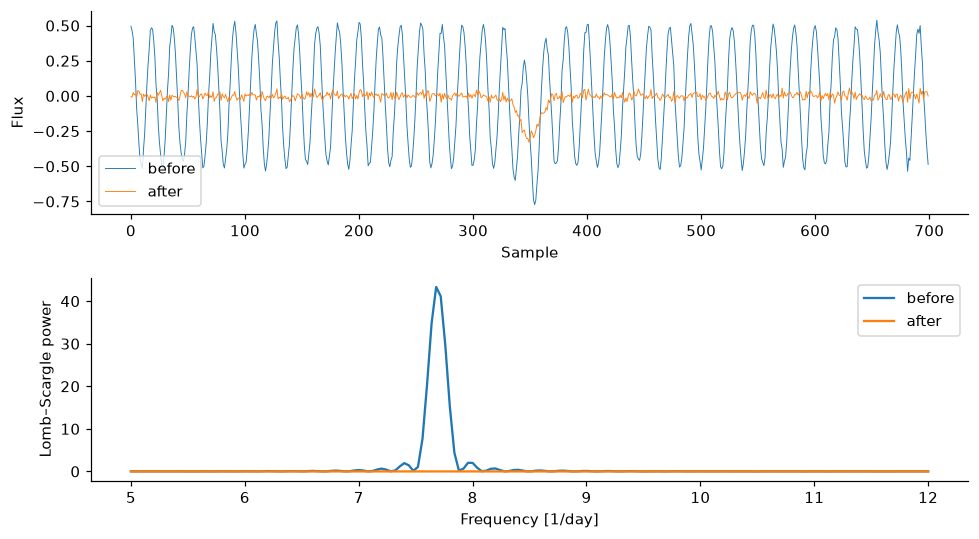

In [2]:
# Generate a 0.13-day pulsation (about 7.69 cycles/day) with white measurement noise.
lc = Nahiku.from_synthetic_noise(duration=5, n_points=700, period=.13, amplitude=.5,
                                 red_noise=0, white_noise=.02, seed=7)

# Inject the same known Gaussian dip for both prewhitening demonstrations.
lc.inject_anomaly(center=2.5, width=.06, depth=.3)

# Copy the injected observations so each method starts with identical input data.
balmung_lc = lc.copy()
masked_lc = lc.copy()

# Use default Balmung fitting on all samples; no method argument is required.
balmung_result = balmung_lc.prewhiten(
    fmin=5, fmax=12, max_components=3, minimum_snr=4,
)

# Inspect the removed frequencies and stopping reason, then plot the diagnostics.
print("Default Balmung:", balmung_result.frequencies, balmung_result.stopping_reason)
balmung_result.plot();

Optional masked method: [7.69215584] minimum_snr


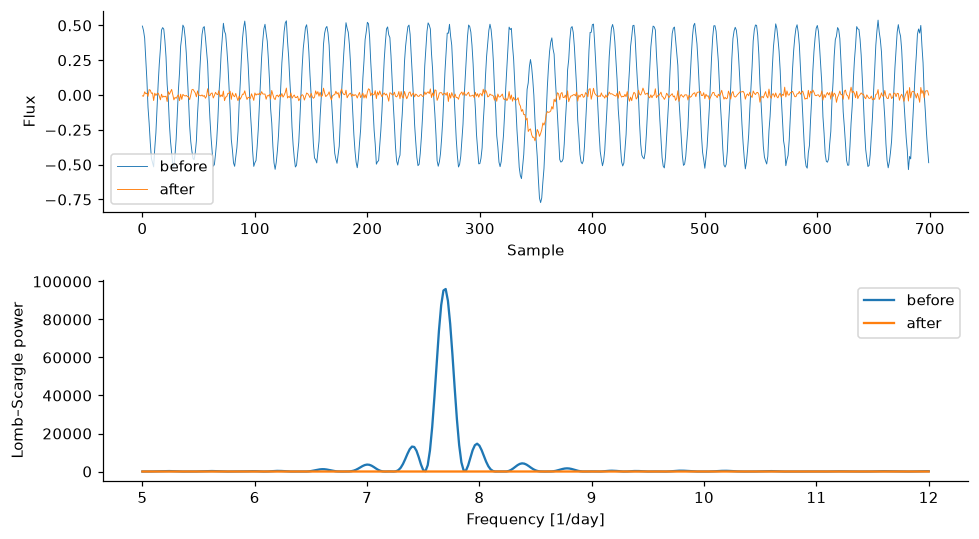

In [3]:
# Optionally protect the known dip by excluding samples within 0.3 day of its center.
fit_mask = np.abs(masked_lc.time - 2.5) > .3

# Select weighted fitting because it supports measurement errors and a fitting mask.
# The fitted sinusoids are subtracted at all timestamps, including the protected region.
masked_result = masked_lc.prewhiten(
    method="weighted", fmin=5, fmax=12, max_components=3, minimum_snr=4,
    fit_mask=fit_mask,
)

# Inspect and plot this independent result; the Balmung result remains unchanged.
print("Optional masked method:", masked_result.frequencies, masked_result.stopping_reason)
masked_result.plot();

## Interpret the result

Both methods should recover the injected pulsation near 7.69 cycles/day. They start from independent copies of the same injected observations, so the second method does not operate on residuals from the first. The parent `lc` remains unchanged by either prewhitening run.

The first run uses Balmung, the default method. Dan Hey's algorithm jointly fits sinusoids without uncertainty weights and uses a threshold fixed from the initial amplitude spectrum. All observations participate in fitting. Its frequency bounds constrain the initial peak selection. The subsequent nonlinear fit is unconstrained.

The optional second run uses `method="weighted"` and excludes the known dip from fitting with `fit_mask`. It refines frequencies locally and recomputes the threshold from the residual spectrum. The fitted signal is still subtracted at all timestamps. The mask uses prior knowledge of the synthetic event; the algorithm does not discover that event. Differences between the results reflect both the fitting method and the mask.

Both methods preserve the continuum and retain diagnostics. Phases refer to each result's `time_origin`. Residual flux is not standardized automatically, and measurement errors do not include uncertainty in fitted pulsations.

Consult the API reference for parameter and return-value details.